<a href="https://colab.research.google.com/github/TheLedAlchemist/ARENA_materials/blob/main/arena_cnns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Installs

In [1]:
!git clone --filter=blob:none --sparse https://github.com/TheLedAlchemist/ARENA_materials.git

Cloning into 'ARENA_materials'...
remote: Enumerating objects: 16184, done.
remote: Counting objects: 100% (228/228), done.
remote: Compressing objects: 100% (82/82), done.
remote: Total 16184 (delta 159), reused 146 (delta 146), pack-reused 15956 (from 3)
Receiving objects: 100% (16184/16184), 1.96 MiB | 18.58 MiB/s, done.
Resolving deltas: 100% (10101/10101), done.
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 11 (delta 0), reused 0 (delta 0), pack-reused 4 (from 1)
Receiving objects: 100% (11/11), 46.02 KiB | 2.56 MiB/s, done.


In [2]:
%cd ARENA_materials
!git sparse-checkout set chapter0_fundamentals

/content/ARENA_materials
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (45/45), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 69 (delta 13), reused 1 (delta 1), pack-reused 24 (from 1)
Receiving objects: 100% (69/69), 1.71 MiB | 13.87 MiB/s, done.
Resolving deltas: 100% (15/15), done.


In [3]:
!pip install torchinfo
!pip install jaxtyping
!pip install einsum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jaxtyping]


# Imports

In [6]:
import json
import sys
from collections import namedtuple
from dataclasses import dataclass
from pathlib import Path

import einops
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchinfo
from IPython.display import display
from jaxtyping import Float, Int
from PIL import Image
from rich import print as rprint
from rich.table import Table
from torch import Tensor
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models
from torchvision.transforms import v2 as transforms
from tqdm.auto import tqdm

# Make sure exercises are in the path
chapter = "chapter0_fundamentals"
section = "part2_cnns"
root_dir = Path("/content/ARENA_materials")
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

MAIN = __name__ == "__main__"

import part2_cnns.tests as tests
import part2_cnns.utils as utils
from fundamentals_utils import CIFAR10
from plotly_utils import line

# On machines with many cores the default of one
# thread per core makes small CPU tensor operations much slower
torch.set_num_threads(min(4, torch.get_num_threads()))


In [ ]:
print(Path.cwd())
print((Path.cwd().parents))
(Path.cwd().parents[0] / chapter)

In [ ]:
[p for p in Path.cwd().parents]

# MLP Setup

## Relu

In [7]:
class MyReLU(nn.Module):
  def __init__(self):
    super().__init__()

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return torch.maximum(x, torch.tensor(0.0))

In [8]:
tests.test_relu(MyReLU)

All tests in `test_relu` passed!


## Standard @ vesion

In [9]:
class Linear(nn.Module):
    def __init__(self, in_features: int, out_features: int, bias=True):
        """
        A simple linear (technically, affine) transformation.

        The fields should be named `weight` and `bias` for compatibility with PyTorch.
        If `bias` is False, set `self.bias` to None.
        """
        super().__init__()
        self.weight = nn.Parameter(
            torch.tensor(
                (torch.rand(out_features, in_features) - 0.5) * 2.0 / np.sqrt(in_features)
            )
        )
        self.bias = None

        if bias:
          self.bias = nn.Parameter((torch.rand(out_features) - 0.5) * 2.0 / np.sqrt(in_features))

    def __call__(self, x: Tensor) -> Tensor:
        return self.forward(x)

    def forward(self, x: Tensor) -> Tensor:
        """
        x: shape (*, in_features)
        Return: shape (*, out_features)
        """
        ret = x @ self.weight.T

        if self.bias is not None:
          ret += self.bias

        return ret

    def extra_repr(self) -> str:
        print(f"Weights shape: {self.weight.shape}\n{self.weight}\n\n")

        if self.bias is not None:
          print(f"Bias shape: {self.bias.shape}\n{self.bias}")

## Einsum version

In [10]:
torch.einsum

<function torch.functional.einsum(*args: Any) -> torch.Tensor>

In [11]:
class EinsumLinear(nn.Module):
    def __init__(self, in_features: int, out_features: int, bias=True):
        """
        A simple linear (technically, affine) transformation.

        The fields should be named `weight` and `bias` for compatibility with PyTorch.
        If `bias` is False, set `self.bias` to None.
        """
        super().__init__()
        self.weight = nn.Parameter(
            torch.tensor(
                (torch.rand(out_features, in_features) - 0.5) * 2.0 / np.sqrt(in_features)
            )
        )
        self.bias = None

        if bias:
          self.bias = nn.Parameter((torch.rand(out_features) - 0.5) * 2.0 / np.sqrt(in_features))

    def __call__(self, x: Tensor) -> Tensor:
        return self.forward(x)

    def forward(self, x: Tensor) -> Tensor:
        """
        x: shape (*, in_features)
        Return: shape (*, out_features)
        """
        ret = torch.einsum("...j,...ij->...i", x, self.weight)

        if self.bias is not None:
          ret += self.bias

        return ret

    def extra_repr(self) -> str:
        print(f"Weights shape: {self.weight.shape}\n{self.weight}\n\n")

        if self.bias is not None:
          print(f"Bias shape: {self.bias.shape}\n{self.bias}")

In [12]:
linear_test = Linear(3, 7, bias=True)
linear_test(torch.rand(2, 15, 3))

einsum_test = EinsumLinear(3, 7, bias=True)
einsum_test(torch.rand(2, 15, 3))

/tmp/ipykernel_2722/3773404872.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(


tensor([[[-0.2348, -0.9440,  0.3890,  0.4281,  0.1672,  0.5358,  0.3627],
         [-0.3723, -1.0755,  0.4637,  0.3854,  0.4204,  0.4606,  0.4094],
         [-0.0695, -0.4905,  0.5167,  0.2547, -0.2284,  0.5221,  0.5020],
         [-0.2208, -1.1029,  0.4252,  0.5236,  0.2767,  0.4481,  0.3324],
         [-0.3810, -0.4182,  0.6482, -0.0513,  0.0817,  0.5053,  0.6918],
         [-0.0965, -1.1227,  0.3542,  0.6447,  0.1380,  0.4747,  0.2496],
         [-0.4773, -0.7838,  0.4368,  0.1415,  0.3136,  0.6058,  0.5112],
         [-0.2533, -1.0698,  0.3766,  0.4912,  0.2622,  0.5115,  0.3271],
         [-0.0720, -0.6069,  0.5753,  0.3076, -0.1208,  0.4320,  0.5006],
         [-0.2706, -0.4150,  0.4659,  0.0719, -0.1124,  0.6445,  0.5622],
         [ 0.1188, -0.8565,  0.7353,  0.5598, -0.0593,  0.1567,  0.4515],
         [-0.0063, -0.8635,  0.5939,  0.5034, -0.0040,  0.3157,  0.4171],
         [-0.5389, -0.7993,  0.1878,  0.1628,  0.2628,  0.8441,  0.3979],
         [-0.0996, -0.4781,  0.6488,  

In [13]:
tests.test_linear_parameters(Linear, bias=False)
tests.test_linear_parameters(Linear, bias=True)
tests.test_linear_forward(Linear, bias=False)
tests.test_linear_forward(Linear, bias=True)

All tests in `test_linear_parameters` passed!
All tests in `test_linear_parameters` passed!
All tests in `test_linear_forward` passed!
All tests in `test_linear_forward` passed!


/tmp/ipykernel_2722/3773404872.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(


In [14]:
torch.tensor(torch.ones(5, 3)) - 0.5

/tmp/ipykernel_2722/3058297645.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(torch.ones(5, 3)) - 0.5


tensor([[0.5000, 0.5000, 0.5000],
        [0.5000, 0.5000, 0.5000],
        [0.5000, 0.5000, 0.5000],
        [0.5000, 0.5000, 0.5000],
        [0.5000, 0.5000, 0.5000]])

## Flatten

In [20]:
class Flatten(nn.Module):
    def __init__(self, start_dim: int = 1, end_dim: int = -1) -> None:
        super().__init__()
        self.start_dim = start_dim
        self.end_dim = end_dim

    def forward(self, input: Tensor) -> Tensor:
        """
        Flatten out dimensions from start_dim to end_dim, inclusive of both.
        """
        shape = input.shape

        # Get start & end dims, handling negative indexing for end dim
        start_dim = self.start_dim
        end_dim = self.end_dim if self.end_dim >= 0 else len(shape) + self.end_dim

        # Get the shapes to the left / right of flattened dims, as well as size of flattened middle
        shape_left = shape[:start_dim]
        shape_right = shape[end_dim + 1 :]
        shape_middle = torch.prod(torch.tensor(shape[start_dim : end_dim + 1])).item()

        return torch.reshape(input, shape_left + (shape_middle,) + shape_right)

    def extra_repr(self) -> str:
        return ", ".join([f"{key}={getattr(self, key)}" for key in ["start_dim", "end_dim"]])


## MNIST MLP

In [57]:
class SimpleMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = Flatten(1, -1)
        self.linear1 = nn.Linear(28 * 28, 100)
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(100, 10)

        # self.model = nn.Sequential(
        #     self.flatten,
        #     self.linear1,
        #     self.relu,
        #     self.linear2
        # )

    def forward(self, x: Tensor) -> Tensor:
        ret = self.flatten(x)
        ret = self.linear1(ret)
        ret = self.relu(ret)
        ret = self.linear2(ret)

        return ret

    def __call__(self, x: Tensor) -> Tensor:
      return self.forward(x)

In [58]:
# Flatten()(torch.rand(28, 28), (28 * 28)).shape

In [59]:
mymlp = SimpleMLP()
mymlp(torch.rand(5, 28, 28))

imgs = torch.rand(5, 1, 28, 28)

mymlp(torch.rand(5, 1, 28, 28))

display(transforms.ToPILImage()(imgs[0]))

In [24]:
mymlp.__dict__

{'training': True,
 '_parameters': {},
 '_buffers': {},
 '_non_persistent_buffers_set': set(),
 '_backward_pre_hooks': OrderedDict(),
 '_backward_hooks': OrderedDict(),
 '_is_full_backward_hook': None,
 '_forward_hooks': OrderedDict(),
 '_forward_hooks_with_kwargs': OrderedDict(),
 '_forward_hooks_always_called': OrderedDict(),
 '_forward_pre_hooks': OrderedDict(),
 '_forward_pre_hooks_with_kwargs': OrderedDict(),
 '_state_dict_hooks': OrderedDict(),
 '_state_dict_pre_hooks': OrderedDict(),
 '_load_state_dict_pre_hooks': OrderedDict(),
 '_load_state_dict_post_hooks': OrderedDict(),
 '_modules': {'flatten': Flatten(start_dim=-2, end_dim=-1),
  'linear1': Linear(in_features=784, out_features=100, bias=True),
  'relu': ReLU(),
  'linear2': Linear(in_features=100, out_features=10, bias=True)}}

In [25]:
%cd /content/ARENA_materials/chapter0_fundamentals/exercises/part2_cnns

/content/ARENA_materials/chapter0_fundamentals/exercises/part2_cnns


In [26]:
tests.test_mlp_module(SimpleMLP)
tests.test_mlp_forward(SimpleMLP)

All tests in `test_mlp_module` passed!
All tests in `test_mlp_forward` passed!


# **Training**

In [43]:
MNIST_TRANSFORM = transforms.Compose(
    [
        transforms.ToImage(),
        transforms.ToDtype(torch.float32, scale=True),
        transforms.Normalize([0.1307], [0.3081]),
    ]
)


def get_mnist(trainset_size: int = 10_000, testset_size: int = 1_000) -> tuple[Subset, Subset]:
    """Returns a subset of MNIST training data."""

    # Get original datasets, which are downloaded to "./data" for future use
    mnist_trainset = datasets.MNIST(exercises_dir / "data", train=True, download=True, transform=MNIST_TRANSFORM)
    mnist_testset = datasets.MNIST(exercises_dir / "data", train=False, download=True, transform=MNIST_TRANSFORM)

    # # Return a subset of the original datasets
    mnist_trainset = Subset(mnist_trainset, indices=range(trainset_size))
    mnist_testset = Subset(mnist_testset, indices=range(testset_size))

    return mnist_trainset, mnist_testset


mnist_trainset, mnist_testset = get_mnist()
mnist_trainloader = DataLoader(mnist_trainset, batch_size=64, shuffle=True)
mnist_testloader = DataLoader(mnist_testset, batch_size=64, shuffle=False)

# Get the first batch of test data, by starting to iterate over `mnist_testloader`
for img_batch, label_batch in mnist_testloader:
    print(f"{img_batch.shape=}\n{label_batch.shape=}\n")
    break

# Get the first datapoint in the test set, by starting to iterate over `mnist_testset`
for img, label in mnist_testset:
    print(f"{img.shape=}\n{label=}\n")
    break

torch.testing.assert_close(img, img_batch[0])
assert label == label_batch[0].item()


img_batch.shape=torch.Size([64, 1, 28, 28])
label_batch.shape=torch.Size([64])

img.shape=torch.Size([1, 28, 28])
label=7



In [44]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")

# If this is CPU, we recommend figuring out how to get cuda access (or MPS if you're on a Mac).
print(device)

cuda


In [70]:
@dataclass
class SimpleMLPTrainingArgs:
    """
    Defining this class implicitly creates an __init__ method, which sets arguments as below, e.g.
    self.batch_size=64. Any of these fields can also be overridden when you create an instance, e.g.
    SimpleMLPTrainingArgs(batch_size=128).
    """

    batch_size: int = 64
    epochs: int = 3
    learning_rate: float = 1e-3


def train(args: SimpleMLPTrainingArgs) -> tuple[list[float], SimpleMLP]:
    """
    Trains & returns the model, using training parameters from the `args` object. Returns the model,
    and loss list.
    """
    model = SimpleMLP().to(device)

    mnist_trainset, _ = get_mnist()
    mnist_trainloader = DataLoader(mnist_trainset, batch_size=args.batch_size, shuffle=True)

    optimizer = torch.optim.Adam(model.parameters(), lr=args.learning_rate)
    loss_list = []

    for epoch in range(args.epochs):
        pbar = tqdm(mnist_trainloader)

        for imgs, labels in pbar:
            # Move data to device, perform forward pass
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs)

            # print(logits.shape, labels.shape)

            # Calculate loss, perform backward pass
            loss = F.cross_entropy(logits, labels)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Update logs & progress bar
            loss_list.append(loss.item())
            pbar.set_postfix(epoch=f"{epoch + 1}/{args.epochs}", loss=f"{loss:.3f}", refresh=False)

    return loss_list, model


args = SimpleMLPTrainingArgs()
loss_list, model = train(args)

# line(
#     loss_list,
#     x_max=args.epochs * len(mnist_trainset),
#     labels={"x": "Examples seen", "y": "Cross entropy loss"},
#     title="SimpleMLP training on MNIST",
#     width=700,
# )


  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

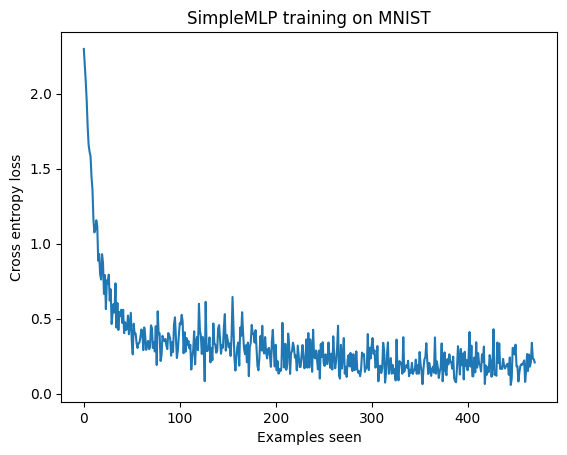

In [71]:
import matplotlib.pyplot as plt

plt.plot(
    loss_list,
    # xlabel={"x": "Examples seen", "y": "Cross entropy loss"},
    # title="SimpleMLP training on MNIST",
    # width=700,
)

plt.xlabel("Examples seen")
plt.ylabel("Cross entropy loss")
plt.title("SimpleMLP training on MNIST")
plt.show()


In [49]:
# torch.argmax(logits, dim=-1)[0]
# logits[0]

tensor([[-0.1034,  0.0649,  0.3583, -0.0486,  0.1909,  0.0396,  0.2035, -0.4173,
         -0.1451,  0.1901]], device='cuda:0', grad_fn=<SelectBackward0>)

In [90]:
def train(args: SimpleMLPTrainingArgs) -> tuple[list[float], list[float], SimpleMLP]:
    """
    Trains the model, using training parameters from the `args` object.

    Returns:
        The model, and lists of loss & accuracy.
    """
    model = SimpleMLP().to(device)

    # Adjusted _ to mnist_testset
    mnist_trainset, mnist_testset = get_mnist()

    mnist_trainloader = DataLoader(mnist_trainset, batch_size=args.batch_size, shuffle=True)

    # I added this guy here
    mnist_testloader = DataLoader(mnist_trainset, batch_size=args.batch_size, shuffle=False)

    optimizer = torch.optim.Adam(model.parameters(), lr=args.learning_rate)
    loss_list = []
    accuracy_list = []

    for epoch in range(args.epochs):
        pbar = tqdm(mnist_trainloader)

        for imgs, labels in pbar:
            # Move data to device, perform forward pass
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs)

            # print(logits.shape, labels.shape)

            # Calculate loss, perform backward pass
            loss = F.cross_entropy(logits, labels)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Update logs & progress bar
            loss_list.append(loss.item())
            pbar.set_postfix(epoch=f"{epoch + 1}/{args.epochs}", loss=f"{loss:.3f}", refresh=False)

        for imgs, labels in mnist_testloader:
          imgs, labels = imgs.to(device), labels.to(device)
          test_logits = model(imgs)

          logits = model(imgs)
          accuracy = (torch.argmax(logits, dim=-1) == labels).float().mean().item()
          accuracy_list.append(accuracy)

    return loss_list, accuracy_list, model

my_args = SimpleMLPTrainingArgs()
my_args.epochs = 16
my_args.batch_size = 128

# args = SimpleMLPTrainingArgs()
loss_list, accuracy_list, model = train(my_args)


  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

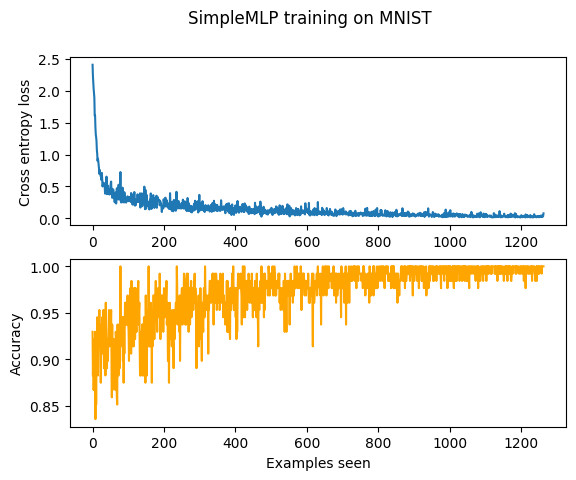

In [91]:
fig, ax = plt.subplots(2, 1)

ax[0].plot(loss_list)
ax[0].set_ylabel("Cross entropy loss")

ax[1].plot(accuracy_list, color="orange")
ax[1].set_ylabel("Accuracy")

fig.suptitle("SimpleMLP training on MNIST")
plt.xlabel("Examples seen")
fig.show()